# Counting Coalitions: The Combinatorics of Shapley Values and the Cost of Explainable ML
**STAT 8030 — Final Project Implementation** · Md Istiak Morsalin, Prianka Barman

This notebook implements everything in the proposal:

| Section | Research question |
|---|---|
| §2 | **RQ1** weight identity $\binom{n-1}{k}k!(n-1-k)!=(n-1)!$, weights sum to 1 |
| §3 | **RQ2** subset formula = permutation formula (hand-sized games, $n=3,4$) |
| §4 | **RQ3** efficiency $\sum_i\phi_i=v(N)-v(\emptyset)$ |
| §5–§9 | **RQ4** exact enumeration vs. permutation sampling vs. KernelSHAP, $n=4\ldots16$ |
| §9b | **Replication**: every headline finding, side by side on UCI Bank Marketing and UCI Adult |

**Value function.** For an instance $x$ and background sample $B$, $v(S)=\frac{1}{|B|}\sum_{b\in B} f(x_S, b_{\bar S})$ (interventional / "baseline" Shapley — the same game SHAP's `Independent` masker uses). All three estimators query the *same* $v$, so differences are purely due to estimation.

> Set `QUICK = True` for a ~2-minute smoke test; set `QUICK = False` for the full two-dataset study (about 2 hours on a Colab CPU; keep the tab open). Results are saved to `results/`.

## 0. Setup & configuration

In [1]:
# Optional: the shap library is only used for a cross-check in §5.1
!pip -q install shap

import time, math, itertools, warnings, os
from itertools import permutations, combinations
from fractions import Fraction
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

In [2]:
QUICK = False            # True = fast smoke test

SEED          = 0
N_BACKGROUND  = 20  if QUICK else 50     # |B| rows used to "remove" features
N_EXPLAIN     = 2   if QUICK else 5      # instances explained per (dataset, model, n)
N_REPEATS     = 2   if QUICK else 3      # random seeds per sampling budget
BUDGETS       = [10, 50, 100, 500, 1000] # m = number of sampled permutations
# Datasets to compare. Bank Marketing (16 features) and Adult (14 features) replicate each other.
# Options: "Bank", "Pima", "California", "Heart", "Adult", "Synthetic16"
USE_DATASETS  = ["Bank", "Adult"]
SCALING_NS    = list(range(4, 13)) if QUICK else list(range(4, 17))   # exact-cost sweep; each dataset stops at its own d
CHUNK_ROWS    = 400_000                  # rows per model.predict call (memory guard)
OUT = "results"; os.makedirs(OUT, exist_ok=True)

def n_grid(d):
    # feature counts used for the accuracy study on a dataset with d features
    if QUICK: return [n for n in (4, 8) if n <= d]
    return sorted(set(range(4, d + 1, 2)) | {d})

## 1. Core combinatorial machinery

* A coalition $S\subseteq N$ is stored as a bitmask integer; `all_masks(n)` lists all $2^n$.
* `shapley_weight(n, k)` $= \dfrac{k!\,(n-k-1)!}{n!}$.
* `exact_shapley_from_table(v)` evaluates Eq. (1) given the full table $v[S]$ — the **subset formula**.
* `permutation_shapley_exact(v)` evaluates the **permutation formula** by brute force over all $n!$ orderings (only for tiny $n$).

In [3]:
def all_masks(n):
    idx = np.arange(2 ** n)
    return ((idx[:, None] >> np.arange(n)) & 1).astype(bool)        # (2^n, n)

def shapley_weight(n, k, exact=False):
    if exact:
        return Fraction(math.factorial(k) * math.factorial(n - k - 1), math.factorial(n))
    return math.factorial(k) * math.factorial(n - k - 1) / math.factorial(n)

def exact_shapley_from_table(v):
    # Subset formula (Eq. 1). v: array of length 2^n indexed by bitmask.
    n = int(round(math.log2(len(v))))
    idx = np.arange(2 ** n)
    sizes = np.array([bin(s).count("1") for s in idx])
    w = np.array([shapley_weight(n, k) for k in range(n)])
    phi = np.zeros(n)
    for i in range(n):
        without = idx[((idx >> i) & 1) == 0]          # S ⊆ N \ {i}
        phi[i] = np.sum(w[sizes[without]] * (v[without | (1 << i)] - v[without]))
    return phi

def permutation_shapley_exact(v, n):
    # Permutation formula: average marginal contribution over all n! orderings.
    phi = [0] * n
    for perm in permutations(range(n)):
        S = 0
        for i in perm:
            phi[i] += v[S | (1 << i)] - v[S]
            S |= 1 << i
    return [p / math.factorial(n) for p in phi]

## 2. RQ1 — the coalition weights form a valid average

Identity: $\binom{n-1}{k}\,k!\,(n-1-k)!=(n-1)!$. Hence each coalition **size** $k$ receives total weight $\binom{n-1}{k}\frac{k!(n-k-1)!}{n!}=\frac1n$, and the $n$ sizes sum to 1 over the $2^{n-1}$ coalitions (binomial theorem). Checked below in exact rational arithmetic.

In [4]:
rows = []
for n in range(1, 21):
    assert all(math.comb(n-1, k) * math.factorial(k) * math.factorial(n-1-k) == math.factorial(n-1)
               for k in range(n))
    per_size = [math.comb(n-1, k) * shapley_weight(n, k, exact=True) for k in range(n)]
    assert all(p == Fraction(1, n) for p in per_size)
    assert sum(math.comb(n-1, k) for k in range(n)) == 2 ** (n-1)
    rows.append({"n": n, "#coalitions 2^(n-1)": 2 ** (n-1), "weight per size": f"1/{n}",
                 "total weight": sum(per_size)})
print("RQ1 identity verified exactly for n = 1..20")
pd.DataFrame(rows).iloc[[0, 1, 2, 3, 7, 15, 19]]

RQ1 identity verified exactly for n = 1..20


,n,#coalitions 2^(n-1),weight per size,total weight
0,1,1,1/1,1
1,2,2,1/2,1
2,3,4,1/3,1
3,4,8,1/4,1
7,8,128,1/8,1
15,16,32768,1/16,1
19,20,524288,1/20,1


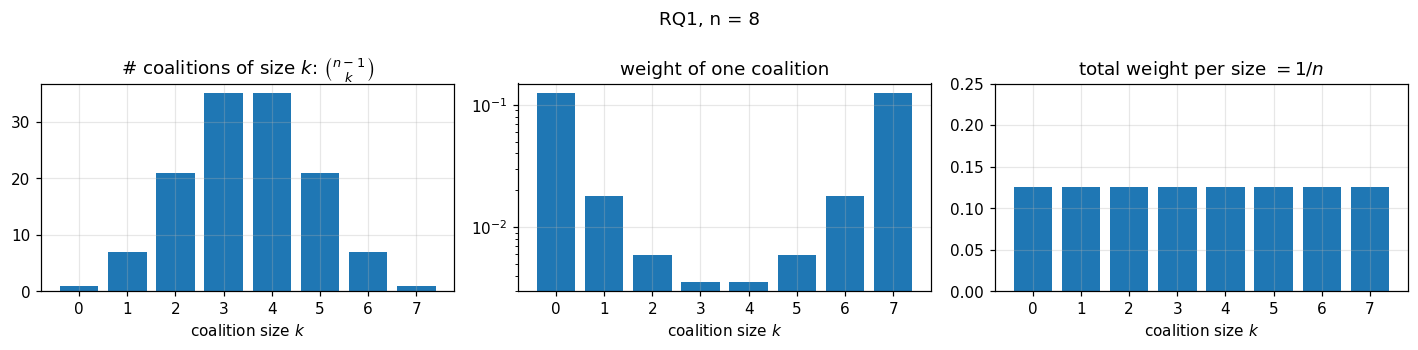

In [5]:
# Visual: for n = 8, coalitions are very unequal in number per size, but each size gets 1/n weight.
n = 8; ks = np.arange(n)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].bar(ks, [math.comb(n-1, k) for k in ks]); ax[0].set_title(r"# coalitions of size $k$: $\binom{n-1}{k}$")
ax[1].bar(ks, [shapley_weight(n, k) for k in ks]); ax[1].set_yscale("log"); ax[1].set_title("weight of one coalition")
ax[2].bar(ks, [math.comb(n-1, k) * shapley_weight(n, k) for k in ks]); ax[2].set_ylim(0, .25)
ax[2].set_title(r"total weight per size $= 1/n$")
for a in ax: a.set_xlabel("coalition size $k$")
plt.suptitle(f"RQ1, n = {n}"); plt.tight_layout(); plt.savefig(f"{OUT}/rq1_weights.png"); plt.show()

## 3. RQ2 — subset formula = permutation formula

**Worked example ($n=3$).** A toy 3-player game. We list all $3!=6$ orderings and each player's marginal contribution, then compare against the subset formula.

In [6]:
# Toy game on N = {1,2,3}; bit i-1 represents player i.
toy = {(): 0, (1,): 10, (2,): 20, (3,): 30, (1, 2): 40, (1, 3): 50, (2, 3): 60, (1, 2, 3): 90}
v3 = np.zeros(8)
for S, val in toy.items():
    v3[sum(1 << (i - 1) for i in S)] = val

table = []
for perm in permutations([1, 2, 3]):
    S, row = 0, {"ordering": "".join(map(str, perm))}
    for i in perm:
        row[f"Δ{i}"] = v3[S | (1 << (i-1))] - v3[S]; S |= 1 << (i-1)
    table.append(row)
df = pd.DataFrame(table)[["ordering", "Δ1", "Δ2", "Δ3"]]
df.loc["mean (permutation formula)"] = ["", *df[["Δ1", "Δ2", "Δ3"]].mean()]
display(df)
print("subset formula   :", exact_shapley_from_table(v3))
print("sum of φ =", exact_shapley_from_table(v3).sum(), "= v(N) - v(∅) =", v3[-1] - v3[0])

,ordering,Δ1,Δ2,Δ3
0,123,10.0,30.0,50.0
1,132,10.0,40.0,40.0
2,213,20.0,20.0,50.0
3,231,30.0,20.0,40.0
4,312,20.0,40.0,30.0
5,321,30.0,30.0,30.0
mean (permutation formula),,20.0,30.0,40.0


subset formula   : [20. 30. 40.]
sum of φ = 90.0 = v(N) - v(∅) = 90.0


In [7]:
# Counting check: the number of orderings in which the predecessors of i are exactly S
# equals |S|!(n-|S|-1)!  — this is the bijection behind RQ2.
def count_check(n):
    for i in range(n):
        counts = {}
        for perm in permutations(range(n)):
            pos = perm.index(i)
            counts[frozenset(perm[:pos])] = counts.get(frozenset(perm[:pos]), 0) + 1
        for S, c in counts.items():
            assert c == math.factorial(len(S)) * math.factorial(n - len(S) - 1)
        assert len(counts) == 2 ** (n - 1)          # every S ⊆ N\{i} occurs
    return True

rng = np.random.default_rng(SEED)
for n in (3, 4, 5, 6):
    count_check(n)
    v = rng.normal(size=2 ** n)                      # arbitrary game
    assert np.allclose(exact_shapley_from_table(v), permutation_shapley_exact(v, n))
print("RQ2 verified: predecessor-set counts match |S|!(n-|S|-1)!, and both formulas agree for n = 3..6")

RQ2 verified: predecessor-set counts match |S|!(n-|S|-1)!, and both formulas agree for n = 3..6


## 4. RQ3 — efficiency $\sum_i \phi_i = v(N)-v(\emptyset)$

Proved in the LaTeX notes by telescoping and by induction. Numerical check on random games, plus a check that each individual ordering telescopes.

In [8]:
rng = np.random.default_rng(SEED)
for n in range(1, 13):
    for _ in range(5):
        v = rng.normal(size=2 ** n)
        assert np.isclose(exact_shapley_from_table(v).sum(), v[-1] - v[0])
# telescoping within a single ordering
n = 6; v = rng.normal(size=2 ** n)
for perm in itertools.islice(permutations(range(n)), 200):
    S, tot = 0, 0.0
    for i in perm:
        tot += v[S | 1 << i] - v[S]; S |= 1 << i
    assert np.isclose(tot, v[-1] - v[0])
print("RQ3 verified on random games (n = 1..12) and per-ordering telescoping")

RQ3 verified on random games (n = 1..12) and per-ordering telescoping


### Figure: RQ2 + RQ3 on the $n=3$ example, and the counting behind RQ4
(a) Each bar is one of the $3!=6$ orderings, split into the players' marginal contributions: every bar reaches $v(N)-v(\\emptyset)=90$ (RQ3), and the mean bar equals the subset-formula values $(20,30,40)$ (RQ2).
(b) Exact cost $2^n$, number of orderings $n!$, and sampling cost $m(n+1)$; dots mark where sampling becomes cheaper than exact. Saved as `results/rq2_rq3_example.pdf`.

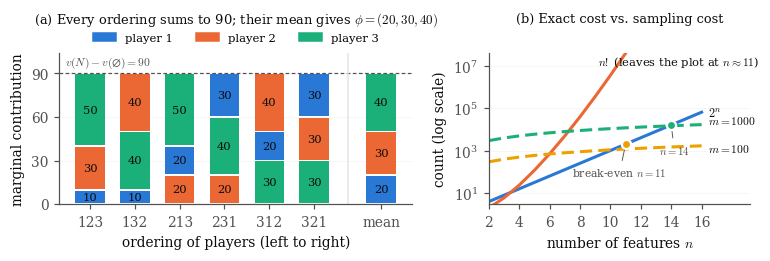

In [9]:
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e0", "#ffffff"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"font.family":"serif","font.size":9,"axes.edgecolor":INK2,"axes.labelcolor":INK,
    "xtick.color":INK2,"ytick.color":INK2,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":False,"mathtext.fontset":"cm"})

v={0:0,1:10,2:20,4:30,3:40,5:50,6:60,7:90}
fig,(a,b)=plt.subplots(1,2,figsize=(7.2,2.45),gridspec_kw={"width_ratios":[1.35,1]})
orders=list(permutations([1,2,3]))
labels=["".join(map(str,p)) for p in orders]+["mean"]
contrib=[]
for p in orders:
    S=0; d={}
    for i in p: d[i]=v[S|1<<(i-1)]-v[S]; S|=1<<(i-1)
    contrib.append(d)
contrib.append({i:np.mean([c[i] for c in contrib]) for i in (1,2,3)})
x=np.arange(7); x=x.astype(float); x[-1]+=0.5
for j,(xx,d) in enumerate(zip(x,contrib)):
    bottom=0
    order=orders[j] if j<6 else (1,2,3)
    for i in order:
        h=d[i]
        a.bar(xx,h-1.2,bottom=bottom+0.6,width=0.66,color=C[i-1],edgecolor="none")
        a.text(xx,bottom+h/2,f"{h:g}",ha="center",va="center",fontsize=7.5,color=INK)
        bottom+=h
a.axhline(90,color=INK2,lw=0.8,ls=(0,(3,2)))
a.text(-0.55,92.5,r"$v(N)-v(\varnothing)=90$",fontsize=7.5,color=INK2,ha="left",va="bottom")
a.axvline(5.75,color=GRID,lw=1)
a.set_xticks(x,labels); a.set_ylim(0,104); a.set_yticks([0,30,60,90])
a.set_xlabel("ordering of players (left to right)"); a.set_ylabel("marginal contribution")
a.grid(axis="y",color=GRID,lw=0.6); a.set_axisbelow(True)
from matplotlib.patches import Patch
a.legend(handles=[Patch(color=C[i],label=f"player {i+1}") for i in range(3)],fontsize=7.5,frameon=False,
         ncol=3,loc="upper center",bbox_to_anchor=(0.5,1.2))
a.set_title("(a) Every ordering sums to 90; their mean gives $\\phi=(20,30,40)$",fontsize=8.5,color=INK,pad=20)
n=np.arange(2,17)
ser=[(2.0**n,r"$2^n$ coalitions (exact)",C[0],"-"),
     (np.array([math.factorial(k) for k in n],float),r"$n!$ orderings",C[1],"-"),
     (1000*(n+1),r"$m(n{+}1)$, $m{=}1000$",C[2],(0,(4,2))),
     (100*(n+1),r"$m(n{+}1)$, $m{=}100$",C[3],(0,(4,2)))]
for y,lab,c,ls in ser:
    b.semilogy(n,y,color=c,lw=2,ls=ls)
for nn,mm,c in ((11,100,C[3]),(14,1000,C[2])):
    b.plot(nn,2.0**nn,"o",ms=6,color=c,mec=SURF,mew=1.5,zorder=5)
b.text(16.4,2**16,r"$2^n$",color=INK,fontsize=8,va="center")
b.text(9.2,1.5e7,r"$n!$ (leaves the plot at $n\approx 11$)",color=INK,fontsize=7.5,va="center")
b.text(16.4,1000*17*1.6,r"$m{=}1000$",color=INK,fontsize=7.5,va="center")
b.text(16.4,100*17*0.8,r"$m{=}100$",color=INK,fontsize=7.5,va="center")
b.annotate("break-even $n{=}11$",(11,2**11),(10.6,60),fontsize=7,color=INK2,ha="center",
           arrowprops=dict(arrowstyle="-",color=INK2,lw=0.6))
b.annotate("$n{=}14$",(14,2**14),(14.2,700),fontsize=7,color=INK2,ha="center",
           arrowprops=dict(arrowstyle="-",color=INK2,lw=0.6))
b.set_ylim(3,4e7); b.set_xlim(2,19.2); b.set_xticks([2,4,6,8,10,12,14,16])
b.set_yticks([1e1,1e3,1e5,1e7])
b.set_xlabel("number of features $n$"); b.set_ylabel("count (log scale)")
b.grid(axis="y",color=GRID,lw=0.6); b.set_axisbelow(True)
b.set_title("(b) Exact cost vs. sampling cost",fontsize=8.5,color=INK,pad=20)
plt.tight_layout(w_pad=1.5)
plt.savefig(f"{OUT}/rq2_rq3_example.pdf"); plt.savefig(f"{OUT}/rq2_rq3_example.png", dpi=200); plt.show()
plt.rcdefaults(); plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

## 5. Data, models, and the value function

**Two datasets are used by default** (`USE_DATASETS` in §0), so every finding is tested twice:

* **UCI Bank Marketing**: 16 features (age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome); target: did the client subscribe to a term deposit? It covers $n=4\\ldots16$.
* **UCI Adult**: 14 features (age, workclass, fnlwgt, education, education-num, marital-status, occupation, relationship, race, sex, capital-gain, capital-loss, hours-per-week, native-country); target: income > \\$50K. It covers $n=4\\ldots14$.

Categorical columns are ordinal-encoded so each original column stays one player; a stratified sample of 12,000 rows per dataset is used for training speed.

Other available datasets (add names to `USE_DATASETS`): Pima Indians Diabetes (8), California Housing (8, target binarized at the median so both models are classifiers), UCI Heart Disease / Cleveland (13), UCI Adult (14, categoricals ordinal-encoded so each original feature stays one player). Because no listed dataset has 15–16 features, a **synthetic** 16-feature classification task (`make_classification`) covers the top of the $n$ range. If a download fails, that dataset is skipped.

To vary $n$ we fix a random feature order per dataset and keep the first $n$ features (nested subsets), retraining both models on each subset. $f(x)$ = predicted probability of the positive class.

In [10]:
from sklearn.datasets import fetch_california_housing, fetch_openml, make_classification

def _pima():
    d = fetch_openml("diabetes", version=1, as_frame=True)
    return d.data.astype(float), (d.target.astype(str) == "tested_positive").astype(int)

def _california():
    d = fetch_california_housing(as_frame=True)
    return d.data.astype(float), (d.target > d.target.median()).astype(int)

def _heart():
    cols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
    try:
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
        d = pd.read_csv(url, names=cols, na_values="?").dropna()
        return d[cols[:-1]].astype(float), (d["num"] > 0).astype(int)
    except Exception:
        d = fetch_openml("heart-statlog", version=1, as_frame=True)   # same 13 attributes
        return d.data.astype(float), (d.target.astype(str) == "present").astype(int)

ADULT_COLS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
              "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
              "hours-per-week", "native-country"]

def _adult():
    try:                                               # OpenML copy (48,842 rows)
        d = fetch_openml("adult", version=2, as_frame=True)
        X, y_raw = d.data[ADULT_COLS].copy(), d.target
    except Exception:                                  # UCI file, then a GitHub mirror of it (32,561 rows)
        X = None
        for url in ("https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
                    "https://raw.githubusercontent.com/shap/shap/master/data/adult.data"):
            try:
                df = pd.read_csv(url, names=ADULT_COLS + ["income"], na_values="?", skipinitialspace=True)
                X, y_raw = df[ADULT_COLS].copy(), df["income"]; break
            except Exception as e:
                print(f"  Adult source failed ({url.split('/')[2]}): {type(e).__name__}")
        if X is None: raise RuntimeError("could not download UCI Adult")
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes        # ordinal; NaN -> -1
    y = y_raw.astype(str).str.contains(">50K").astype(int)
    X, _, y, _ = train_test_split(X, y, train_size=12000, stratify=y, random_state=SEED)
    return X.astype(float), y

BANK_COLS = ["age", "job", "marital", "education", "default", "balance", "housing", "loan",
             "contact", "day", "month", "duration", "campaign", "pdays", "previous", "poutcome"]

def _prep_bank(X, y_raw):
    X = X.copy()
    if list(X.columns) != BANK_COLS and X.shape[1] == 16:
        X.columns = BANK_COLS                      # OpenML names them V1..V16
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes
    y_raw = pd.Series(y_raw).astype(str).str.strip().str.strip('"')
    pos = "yes" if "yes" in set(y_raw) else y_raw.value_counts().idxmin()   # minority class = "yes"
    y = (y_raw == pos).astype(int)
    X, _, y, _ = train_test_split(X, y, train_size=12000, stratify=y, random_state=SEED)
    return X.astype(float).reset_index(drop=True), y.reset_index(drop=True)

def _bank():
    try:                                           # OpenML copy of UCI "bank-full" (45,211 rows)
        d = fetch_openml(data_id=1461, as_frame=True)
        return _prep_bank(d.data, d.target)
    except Exception:                              # fallback: the original UCI archive
        import io, zipfile, urllib.request
        raw = urllib.request.urlopen("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip").read()
        outer = zipfile.ZipFile(io.BytesIO(raw))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank.zip")))
        df = pd.read_csv(inner.open("bank-full.csv"), sep=";")
        return _prep_bank(df[BANK_COLS], df["y"])

def _synthetic():
    X, y = make_classification(n_samples=6000, n_features=16, n_informative=8, n_redundant=4,
                               n_clusters_per_class=2, random_state=SEED)
    return pd.DataFrame(X, columns=[f"x{j}" for j in range(16)]), pd.Series(y)

DATASETS = {}
for name, fn in [("Bank", _bank), ("Pima", _pima), ("California", _california), ("Heart", _heart),
                 ("Adult", _adult), ("Synthetic16", _synthetic)]:
    if name not in USE_DATASETS: continue
    try:
        X, y = fn(); DATASETS[name] = (X.reset_index(drop=True), y.reset_index(drop=True))
        print(f"loaded {name:12s} n_rows={len(X):6d}  d={X.shape[1]:2d}  pos.rate={y.mean():.2f}")
    except Exception as e:
        print(f"[skipped] {name}: {type(e).__name__}: {e}")
assert DATASETS, "No dataset loaded - check your internet connection or USE_DATASETS"

loaded Bank         n_rows= 12000  d=16  pos.rate=0.12
loaded Adult        n_rows= 12000  d=14  pos.rate=0.24


In [11]:
MODELS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "GBT":    lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=SEED),
}

_model_cache = {}
def get_setup(ds, n, model_name):
    # Train `model_name` on the first n features (fixed random order) of dataset `ds`.
    key = (ds, n, model_name)
    if key not in _model_cache:
        X, y = DATASETS[ds]
        order = np.random.default_rng(SEED).permutation(X.shape[1])[:n]
        Xn = X.iloc[:, order].to_numpy(float)
        Xtr, Xte, ytr, yte = train_test_split(Xn, y.to_numpy(), test_size=0.25, stratify=y, random_state=SEED)
        m = MODELS[model_name]().fit(Xtr, ytr)
        r = np.random.default_rng(SEED + n)
        bg = Xtr[r.choice(len(Xtr), N_BACKGROUND, replace=False)]
        ex = Xte[r.choice(len(Xte), N_EXPLAIN, replace=False)]
        auc = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
        _model_cache[key] = dict(f=lambda Z, m=m: m.predict_proba(Z)[:, 1], bg=bg, explain=ex,
                                 auc=auc, features=list(X.columns[order]))
    return _model_cache[key]

class Game:
    # v(S) = mean_b f(x_S, b_{N\S}); counts how many coalitions were evaluated.
    def __init__(self, f, x, bg):
        self.f, self.x, self.bg, self.n, self.evals = f, np.asarray(x, float), np.asarray(bg, float), len(x), 0
    def value(self, masks):
        masks = np.atleast_2d(masks); k, b = len(masks), len(self.bg)
        out, step = np.empty(k), max(1, CHUNK_ROWS // b)
        for s in range(0, k, step):
            M = masks[s:s + step]
            Z = np.where(M[:, None, :], self.x[None, None, :], self.bg[None, :, :])
            out[s:s + step] = self.f(Z.reshape(-1, self.n)).reshape(len(M), b).mean(1)
        self.evals += k
        return out

## 6. The three estimators

**Exact** — enumerate all $2^n$ coalitions once, then apply the subset formula.

**Permutation sampling** (Castro et al., 2009; Štrumbelj & Kononenko, 2014) — draw $m$ uniform orderings $\pi_1..\pi_m$, $\hat\phi_i=\frac1m\sum_t[v(P_i^{\pi_t}\cup\{i\})-v(P_i^{\pi_t})]$. One ordering costs $n+1$ coalition evaluations, so the budget is $E=m(n+1)$. Unbiased by RQ2.

**KernelSHAP** (Lundberg & Lee, 2017) — sample coalitions from the Shapley-kernel size distribution $p(k)\propto\frac{n-1}{k(n-k)}$, $1\le k\le n-1$, with paired (complement) sampling, and solve the least-squares problem $\min_\phi\sum_S (v(S)-v(\emptyset)-\sum_{i\in S}\phi_i)^2$ subject to $\sum_i\phi_i=v(N)-v(\emptyset)$. It receives the **same** number of evaluations $E$.

In [12]:
def exact_shapley(game):
    v = game.value(all_masks(game.n))
    return exact_shapley_from_table(v)

def permutation_sampling(game, m, rng):
    n = game.n
    perms = np.argsort(rng.random((m, n)), axis=1)                 # m uniform random orderings
    masks = np.zeros((m, n + 1, n), bool)
    for t in range(1, n + 1):
        masks[:, t] = masks[:, t - 1]
        masks[np.arange(m), t, perms[:, t - 1]] = True             # add player perms[:, t-1]
    v = game.value(masks.reshape(-1, n)).reshape(m, n + 1)
    phi = np.zeros(n)
    np.add.at(phi, perms.ravel(), (v[:, 1:] - v[:, :-1]).ravel())  # marginal contributions
    return phi / m

def kernel_shap(game, n_evals, rng):
    n = game.n
    v0, vN = game.value(np.array([np.zeros(n, bool), np.ones(n, bool)]))
    k = max((n_evals - 2) // 2, n)                                  # paired samples
    sizes = np.arange(1, n)
    p = (n - 1) / (sizes * (n - sizes)); p /= p.sum()
    s = rng.choice(sizes, size=k, p=p)
    Z = np.argsort(np.argsort(rng.random((k, n)), 1), 1) < s[:, None]  # random subset of size s
    Z = np.vstack([Z, ~Z])
    y = game.value(Z) - v0
    Zf = Z.astype(float)
    A = Zf[:, :-1] - Zf[:, [-1]]                                   # eliminate φ_n via efficiency
    b = y - Zf[:, -1] * (vN - v0)
    coef = np.linalg.lstsq(A, b, rcond=None)[0]
    return np.append(coef, (vN - v0) - coef.sum())

def compare(phi_hat, phi):
    err = phi_hat - phi
    tau = kendalltau(np.abs(phi_hat), np.abs(phi))[0]
    top = lambda a: set(np.argsort(-np.abs(a))[:3])
    return dict(mae=np.mean(np.abs(err)),
                rel_err=np.sum(np.abs(err)) / max(np.sum(np.abs(phi)), 1e-12),
                kendall_tau=1.0 if np.isnan(tau) else tau,
                top3=len(top(phi_hat) & top(phi)) / 3)

### 6.1 Sanity checks: efficiency on a real model, and agreement with the `shap` library

In [13]:
ds0 = "Pima" if "Pima" in DATASETS else next(iter(DATASETS))
st = get_setup(ds0, 6, "GBT")
g = Game(st["f"], st["explain"][0], st["bg"])
phi = exact_shapley(g)
print(f"{ds0}, n=6, GBT  φ =", np.round(phi, 4))
print("Σφ =", phi.sum().round(6), "  v(N)-v(∅) =", (g.value(np.ones(6, bool)) - g.value(np.zeros(6, bool)))[0].round(6))
print("perm. sampling (m=5000):", np.round(permutation_sampling(g, 5000, np.random.default_rng(1)), 4))
print("KernelSHAP     (E=5000):", np.round(kernel_shap(g, 5000, np.random.default_rng(1)), 4))

try:
    import shap
    masker = shap.maskers.Independent(st["bg"], max_samples=len(st["bg"]))
    sv = shap.explainers.Exact(st["f"], masker)(st["explain"][:1]).values[0]
    print("shap ExactExplainer      :", np.round(sv, 4), "| max |diff| =", np.abs(sv - phi).max())
except Exception as e:
    print("shap cross-check skipped:", e)

Bank, n=6, GBT  φ = [-0.028  -0.0416  0.0242  0.0029  0.      0.    ]
Σφ = -0.042457   v(N)-v(∅) = -0.042457
perm. sampling (m=5000): [-0.0281 -0.0415  0.0246  0.003  -0.0004  0.    ]
KernelSHAP     (E=5000): [-0.028  -0.0418  0.024   0.0035 -0.0004  0.0002]
shap ExactExplainer      : [-0.028  -0.0416  0.0242  0.0029  0.      0.    ] | max |diff| = 2.0816681711721685e-17


### 6.2 One client, explained (poster panel)
Exact Shapley values for **one real prediction** with all features: a client who did subscribe and whom the tree model correctly flagged (the median-confidence one, so it is typical rather than extreme).
The bars must add up from the base rate $v(\emptyset)$ to the prediction $f(x)$ — efficiency (RQ3) on real data.
Saves `results/client_explanation.csv`, which the poster figure is drawn from. Takes about a minute ($2^{16}$ coalitions).

Bank: client #2451 | subscribed = 1 | 65,536 coalitions in 74.9s
base rate v(∅) = 0.1766   prediction f(x) = 0.7855
v(∅) + Σφ = 0.785464   (efficiency check: |diff| = 0.0e+00)


,label,phi
0,duration = 1272,0.5610
1,day = 26,0.0986
2,contact = unknown,-0.0881
3,marital = divorced,0.0739
4,balance = 1145,0.0414
5,housing = yes,-0.0274
6,age = 31,-0.0262
7,campaign = 4,-0.0221
8,pdays = -1,-0.0179
9,poutcome = unknown,0.0145


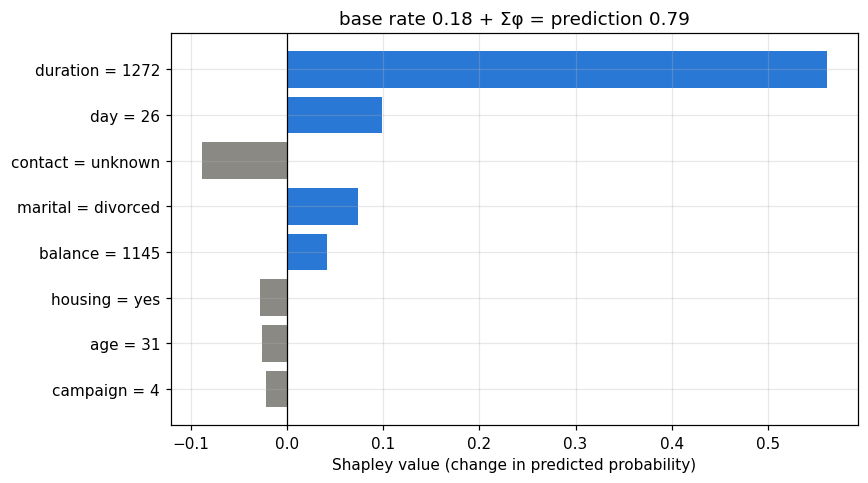

In [14]:
ds = "Bank" if "Bank" in DATASETS else next(iter(DATASETS))
X_all, y_all = DATASETS[ds]
n_all = X_all.shape[1]
st = get_setup(ds, n_all, "GBT")

# Rebuild the same held-out split that get_setup used, to pick a real client from the test set
order = np.random.default_rng(SEED).permutation(n_all)[:n_all]
Xn = X_all.iloc[:, order].to_numpy(float)
_, Xte, _, yte = train_test_split(Xn, y_all.to_numpy(), test_size=0.25, stratify=y_all, random_state=SEED)
p_te = st["f"](Xte)
flagged = np.where((yte == 1) & (p_te >= 0.5))[0]            # subscribed AND predicted "yes"
pick = flagged[np.argsort(p_te[flagged])[len(flagged) // 2]]  # median confidence = a typical case
x = Xte[pick]

g = Game(st["f"], x, st["bg"])
t0 = time.perf_counter(); phi = exact_shapley(g); secs = time.perf_counter() - t0
n_coal = g.evals
v0, vN = g.value(np.array([np.zeros(n_all, bool), np.ones(n_all, bool)]))
print(f"{ds}: client #{pick} | subscribed = {yte[pick]} | {n_coal:,} coalitions in {secs:.1f}s")
print(f"base rate v(∅) = {v0:.4f}   prediction f(x) = {vN:.4f}")
print(f"v(∅) + Σφ = {v0 + phi.sum():.6f}   (efficiency check: |diff| = {abs(v0 + phi.sum() - vN):.1e})")

# Human-readable feature values: undo the ordinal codes used for categorical columns
def _bank_category_labels():
    try:
        d = fetch_openml(data_id=1461, as_frame=True); raw = d.data.copy()
        if list(raw.columns) != BANK_COLS and raw.shape[1] == 16: raw.columns = BANK_COLS
    except Exception:
        import io, zipfile, urllib.request
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
            "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip").read()))
        raw = pd.read_csv(zipfile.ZipFile(io.BytesIO(z.read("bank.zip"))).open("bank-full.csv"), sep=";")[BANK_COLS]
    return {c: dict(enumerate(raw[c].astype("category").cat.categories))
            for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])}

cat_labels = _bank_category_labels() if ds == "Bank" else {}
def _label(name, val):
    if name in cat_labels: return f"{name} = {cat_labels[name].get(int(val), int(val))}"
    return f"{name} = {int(val) if float(val).is_integer() else round(float(val), 2)}"

expl = pd.DataFrame({"feature": st["features"], "label": [_label(f, v) for f, v in zip(st["features"], x)],
                     "phi": phi})
expl = expl.reindex(expl.phi.abs().sort_values(ascending=False).index).reset_index(drop=True)
expl["base"], expl["prediction"], expl["subscribed"] = v0, vN, int(yte[pick])
expl.to_csv(f"{OUT}/client_explanation.csv", index=False)
display(expl[["label", "phi"]].round(4))

# Quick preview (the poster version is redrawn from the CSV)
top = expl.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.label, top.phi, color=np.where(top.phi > 0, "#2a78d6", "#8a8984"))
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Shapley value (change in predicted probability)",
       title=f"base rate {v0:.2f} + Σφ = prediction {vN:.2f}")
plt.tight_layout(); plt.savefig(f"{OUT}/client_explanation_preview.png", dpi=150); plt.show()


## 7. RQ4(a) — the exponential cost of exact Shapley values

Exact computation needs $2^n$ coalition values, each costing $|B|$ model predictions. We time it on every dataset, for $n=4$ up to its number of features (one instance, both models).

In [15]:
scale_rows = []
for ds in DATASETS:
    d_max = DATASETS[ds][0].shape[1]
    for model_name in MODELS:
        for n in SCALING_NS:
            if n > d_max: continue
            st = get_setup(ds, n, model_name)
            g = Game(st["f"], st["explain"][0], st["bg"])
            t0 = time.perf_counter(); exact_shapley(g); dt = time.perf_counter() - t0
            scale_rows.append(dict(dataset=ds, model=model_name, n=n, coalitions=g.evals,
                                   predictions=g.evals * N_BACKGROUND, seconds=dt))
            print(f"{ds:8s} {model_name:6s} n={n:2d}  coalitions={g.evals:6d}  time={dt:7.3f}s")
scale_df = pd.DataFrame(scale_rows); scale_df.to_csv(f"{OUT}/exact_scaling.csv", index=False)

Bank     LogReg n= 4  coalitions=    16  time=  0.001s
Bank     LogReg n= 5  coalitions=    32  time=  0.001s
Bank     LogReg n= 6  coalitions=    64  time=  0.002s
Bank     LogReg n= 7  coalitions=   128  time=  0.002s
Bank     LogReg n= 8  coalitions=   256  time=  0.004s
Bank     LogReg n= 9  coalitions=   512  time=  0.008s
Bank     LogReg n=10  coalitions=  1024  time=  0.019s
Bank     LogReg n=11  coalitions=  2048  time=  0.064s
Bank     LogReg n=12  coalitions=  4096  time=  0.081s
Bank     LogReg n=13  coalitions=  8192  time=  0.149s
Bank     LogReg n=14  coalitions= 16384  time=  0.271s
Bank     LogReg n=15  coalitions= 32768  time=  0.520s
Bank     LogReg n=16  coalitions= 65536  time=  1.056s
Bank     GBT    n= 4  coalitions=    16  time=  0.022s
Bank     GBT    n= 5  coalitions=    32  time=  0.046s
Bank     GBT    n= 6  coalitions=    64  time=  0.092s
Bank     GBT    n= 7  coalitions=   128  time=  0.174s
Bank     GBT    n= 8  coalitions=   256  time=  0.347s
Bank     G

Adult    GBT   : fitted growth ≈ ×1.91 runtime per extra feature (theory: ×2)
Adult    LogReg: fitted growth ≈ ×2.10 runtime per extra feature (theory: ×2)
Bank     GBT   : fitted growth ≈ ×2.00 runtime per extra feature (theory: ×2)
Bank     LogReg: fitted growth ≈ ×1.99 runtime per extra feature (theory: ×2)


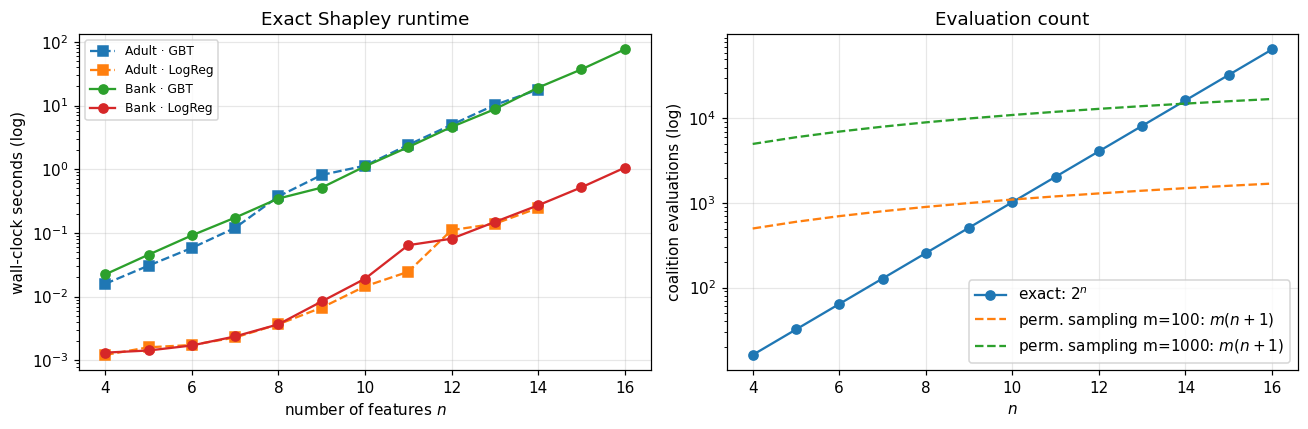

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
growth = {}
for (ds, mname), d in scale_df.groupby(["dataset", "model"]):
    ax[0].semilogy(d.n, d.seconds, "o-" if ds == list(DATASETS)[0] else "s--", label=f"{ds} · {mname}")
    fit = d[d.n >= 8]
    growth[(ds, mname)] = 2 ** np.polyfit(fit.n, np.log2(fit.seconds), 1)[0]
    print(f"{ds:8s} {mname:6s}: fitted growth ≈ ×{growth[(ds, mname)]:.2f} runtime per extra feature (theory: ×2)")
ax[0].set(xlabel="number of features $n$", ylabel="wall-clock seconds (log)", title="Exact Shapley runtime")
ax[0].legend(fontsize=8)
ns = np.arange(4, scale_df.n.max() + 1)
ax[1].semilogy(ns, 2.0 ** ns, "o-", label=r"exact: $2^n$")
for m in (100, 1000):
    ax[1].semilogy(ns, m * (ns + 1), "--", label=f"perm. sampling m={m}: $m(n+1)$")
ax[1].set(xlabel="$n$", ylabel="coalition evaluations (log)", title="Evaluation count"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/rq4_exact_cost.png"); plt.show()

## 8. RQ4(b) — accuracy vs. budget

For every dataset × model × $n$: compute exact $\phi$ for each explained instance, then run both approximations for every budget $m$ and seed. Metrics against exact: MAE, relative $\ell_1$ error $\|\hat\phi-\phi\|_1/\|\phi\|_1$, Kendall's $\tau$ on $|\phi|$ rankings, top-3 overlap, and wall-clock time.

In [ ]:
rows = []
t_start = time.perf_counter()
for ds, (X, _) in DATASETS.items():
    for model_name in MODELS:
        for n in n_grid(X.shape[1]):
            st = get_setup(ds, n, model_name)
            for j, x in enumerate(st["explain"]):
                g = Game(st["f"], x, st["bg"])
                t0 = time.perf_counter(); phi = exact_shapley(g); t_exact = time.perf_counter() - t0
                for m in BUDGETS:
                    E = m * (n + 1)
                    for rep in range(N_REPEATS):
                        for method in ("Permutation", "KernelSHAP"):
                            rng = np.random.default_rng(10_000 * rep + 7 * m + j)
                            gg = Game(st["f"], x, st["bg"])
                            t0 = time.perf_counter()
                            ph = permutation_sampling(gg, m, rng) if method == "Permutation" else kernel_shap(gg, E, rng)
                            dt = time.perf_counter() - t0
                            rows.append(dict(dataset=ds, model=model_name, n=n, instance=j, m=m,
                                             evals=gg.evals, method=method, rep=rep, seconds=dt,
                                             exact_seconds=t_exact, auc=st["auc"], **compare(ph, phi)))
            print(f"done {ds:12s} {model_name:6s} n={n:2d}  AUC={st['auc']:.3f}  "
                  f"[{time.perf_counter() - t_start:6.0f}s elapsed]")
res = pd.DataFrame(rows); res.to_csv(f"{OUT}/approximation_results.csv", index=False)
res.head()

done Bank         LogReg n= 4  AUC=0.802  [     2s elapsed]
done Bank         LogReg n= 6  AUC=0.802  [     6s elapsed]
done Bank         LogReg n= 8  AUC=0.813  [    12s elapsed]
done Bank         LogReg n=10  AUC=0.837  [    20s elapsed]
done Bank         LogReg n=12  AUC=0.860  [    30s elapsed]
done Bank         LogReg n=14  AUC=0.867  [    44s elapsed]
done Bank         LogReg n=16  AUC=0.865  [    65s elapsed]
done Bank         GBT    n= 4  AUC=0.844  [   379s elapsed]
done Bank         GBT    n= 6  AUC=0.853  [   764s elapsed]
done Bank         GBT    n= 8  AUC=0.858  [  1259s elapsed]


In [ ]:
summary = (res.groupby(["dataset", "model", "n", "method", "m"])
              [["mae", "rel_err", "kendall_tau", "top3", "seconds", "exact_seconds"]].mean().reset_index())
summary.to_csv(f"{OUT}/summary.csv", index=False)

# Largest n available per dataset
big = summary[summary.n == summary.groupby("dataset").n.transform("max")]
dsets = list(DATASETS)
fig, axes = plt.subplots(len(MODELS), len(dsets), figsize=(3.6 * len(dsets), 3.2 * len(MODELS)), squeeze=False)
for r, model_name in enumerate(MODELS):
    for c, ds in enumerate(dsets):
        a, d = axes[r, c], big[(big.dataset == ds) & (big.model == model_name)]
        for meth, dm in d.groupby("method"):
            a.loglog(dm.m, dm.mae, "o-", label=meth)
        if len(d):
            m0 = d.m.min(); y0 = d[(d.method == "Permutation") & (d.m == m0)].mae.iloc[0]
            a.loglog(BUDGETS, y0 * np.sqrt(m0 / np.array(BUDGETS)), "k:", label=r"$\propto 1/\sqrt{m}$")
            a.set_title(f"{ds} (n={d.n.iloc[0]}) · {model_name}", fontsize=9)
        a.set_xlabel("permutations $m$  (KernelSHAP: same evals)")
        if c == 0: a.set_ylabel("MAE vs exact")
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/rq4_mae_vs_budget.png"); plt.show()

In [ ]:
dsets = list(summary.dataset.unique())
agg = summary.groupby(["dataset", "method", "m"])[["kendall_tau", "top3", "rel_err"]].mean().reset_index()
fig, ax = plt.subplots(len(dsets), 3, figsize=(14, 3.4 * len(dsets)), squeeze=False)
for r, ds in enumerate(dsets):
    for meth, d in agg[agg.dataset == ds].groupby("method"):
        ax[r, 0].semilogx(d.m, d.rel_err, "o-", label=meth)
        ax[r, 1].semilogx(d.m, d.kendall_tau, "o-", label=meth)
        ax[r, 2].semilogx(d.m, d.top3, "o-", label=meth)
    ax[r, 0].set(title=f"{ds}: relative $\\ell_1$ error", xlabel="$m$"); ax[r, 0].set_yscale("log")
    ax[r, 1].set(title=f"{ds}: Kendall $\\tau$ (ranking of $|\\phi|$)", xlabel="$m$", ylim=(0, 1.02))
    ax[r, 2].set(title=f"{ds}: top-3 feature overlap", xlabel="$m$", ylim=(0, 1.02))
    ax[r, 0].legend()
plt.suptitle("Averaged over both models and all n, per dataset"); plt.tight_layout()
plt.savefig(f"{OUT}/rq4_rankings.png"); plt.show()

In [ ]:
# Error as a function of BOTH n and the budget (permutation sampling vs KernelSHAP), one row per dataset
dsets = list(summary.dataset.unique())
fig, ax = plt.subplots(len(dsets), 2, figsize=(12, 3.8 * len(dsets)), squeeze=False)
for r, ds in enumerate(dsets):
    for a, meth in zip(ax[r], ["Permutation", "KernelSHAP"]):
        piv = summary[(summary.dataset == ds) & (summary.method == meth)].pivot_table(
            index="n", columns="m", values="rel_err", aggfunc="mean")
        im = a.imshow(np.log10(piv.values), aspect="auto", cmap="viridis_r", origin="lower", vmin=-3.7, vmax=-0.5)
        a.set_xticks(range(len(piv.columns)), piv.columns); a.set_yticks(range(len(piv.index)), piv.index)
        for (k, j), val in np.ndenumerate(piv.values):
            a.text(j, k, f"{val:.3f}", ha="center", va="center", fontsize=7,
                   color="w" if np.log10(val) > -2.1 else "k")
        a.grid(False); a.set(title=f"{ds} · {meth}: relative error", xlabel="$m$", ylabel="$n$")
plt.colorbar(im, ax=ax, label=r"$\log_{10}$ rel. error")
plt.savefig(f"{OUT}/rq4_heatmap.png", bbox_inches="tight"); plt.show()

In [ ]:
# Runtime: approximations vs exact, as n grows (at fixed budgets), one panel per dataset
dsets = list(summary.dataset.unique())
fig, ax = plt.subplots(1, len(dsets), figsize=(7 * len(dsets), 4), squeeze=False)
for a, ds in zip(ax[0], dsets):
    t = summary[summary.dataset == ds].groupby(["n", "method", "m"])[["seconds", "exact_seconds"]].mean().reset_index()
    ex = t.groupby("n").exact_seconds.mean()
    a.semilogy(ex.index, ex.values, "k-o", lw=2, label="exact (2^n)")
    for (meth, m), d in t[t.m.isin([100, 1000])].groupby(["method", "m"]):
        a.semilogy(d.n, d.seconds, "--o" if meth == "KernelSHAP" else "-s", ms=4, label=f"{meth}, m={m}")
    a.set(xlabel="$n$", ylabel="seconds per explanation (log)", title=f"{ds}: runtime vs. number of features")
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/rq4_runtime.png"); plt.show()

## 9. A practical rule of thumb

**Empirical.** For each dataset, model, $n$ and method, the smallest $m$ in the grid whose *average* relative error is $\le\varepsilon$ and whose Kendall $\tau\ge0.9$.

**Theoretical (Hoeffding).** Each sampled marginal contribution lies in $[a_i,b_i]$ with range $R$ (for a probability output, $v\in[0,1]$ so $R\le 2$ always works). The permutation estimator is an average of $m$ i.i.d. bounded terms, so with a union bound over $n$ features,
$$\Pr\Big(\max_i|\hat\phi_i-\phi_i|\ge\varepsilon\Big)\le 2n\,e^{-2m\varepsilon^2/R^2}\quad\Longrightarrow\quad m\ \ge\ \frac{R^2}{2\varepsilon^2}\ln\frac{2n}{\delta}.$$
We estimate $R$ empirically from the observed marginal contributions — the bound is conservative because the actual variance is much smaller than $R^2/4$.

In [ ]:
def rule_of_thumb(eps=0.05, tau_min=0.9):
    out = []
    for (ds, model, meth, n), d in summary.groupby(["dataset", "model", "method", "n"]):
        d = d.groupby("m")[["rel_err", "kendall_tau"]].mean()
        ok = d[(d.rel_err <= eps) & (d.kendall_tau >= tau_min)]
        out.append(dict(dataset=ds, model=model, method=meth, n=n,
                        min_m=int(ok.index.min()) if len(ok) else f">{max(BUDGETS)}"))
    return pd.DataFrame(out).pivot(index=["dataset", "model", "method"], columns="n", values="min_m")

for eps in (0.10, 0.05):
    print(f"\nSmallest m with mean relative error ≤ {eps:.0%} and Kendall τ ≥ 0.9")
    rt = rule_of_thumb(eps); display(rt)
    rt.to_csv(f"{OUT}/rule_of_thumb_{int(eps * 100)}pct.csv")

In [ ]:
# Hoeffding-based budget, with R estimated from one instance's marginal contributions (trees, every dataset)
def hoeffding_m(R, eps, n, delta=0.05):
    return math.ceil(R ** 2 / (2 * eps ** 2) * math.log(2 * n / delta))

hrows = []
for ds in DATASETS:
    for n in sorted(summary[summary.dataset == ds].n.unique()):
        st = get_setup(ds, n, "GBT"); g = Game(st["f"], st["explain"][0], st["bg"])
        v = g.value(all_masks(n)); idx = np.arange(2 ** n)
        contrib = np.concatenate([v[idx[((idx >> i) & 1) == 0] | 1 << i] - v[idx[((idx >> i) & 1) == 0]]
                                  for i in range(n)])
        R = contrib.max() - contrib.min()
        hrows.append(dict(dataset=ds, n=n, R=round(R, 3),
                          m_eps_0_05=hoeffding_m(R, 0.05, n), m_eps_0_02=hoeffding_m(R, 0.02, n)))
pd.DataFrame(hrows)

## 9b. Replication: does each finding hold on both datasets?
One row per headline finding, one column per dataset (and model where it matters). If the two datasets agree, the finding is not a quirk of one dataset. Saved as `results/replication_summary.csv`.

In [ ]:
def first_faster(sub, m):
    # smallest n at which sampling with budget m is faster than exact (wall clock), else None
    t = sub[sub.m == m].groupby("n")[["seconds", "exact_seconds"]].mean()
    hit = t[t.seconds < t.exact_seconds]
    return int(hit.index.min()) if len(hit) else f"> {int(t.index.max())}"

def predicted_breakeven(m):
    return next(n for n in range(2, 40) if m * (n + 1) < 2 ** n)

rows = []
auc = res.groupby(["dataset", "model", "n"]).auc.first()
for ds in summary.dataset.unique():
    S = summary[summary.dataset == ds]
    n_max = S.n.max()
    for model in MODELS:
        M = S[S.model == model]
        p = M.pivot_table(index=["n", "m"], columns="method", values="rel_err")
        ratio = (p.Permutation / p.KernelSHAP)
        rule = rule_of_thumb(0.05).loc[(ds, model)]
        rows += [
            dict(dataset=ds, model=model, finding="test AUC at largest n", value=round(auc.loc[(ds, model, n_max)], 3)),
            dict(dataset=ds, model=model, finding="exact runtime growth per feature (theory ×2)",
                 value=round(growth[(ds, model)], 2)),
            dict(dataset=ds, model=model, finding=f"exact seconds per explanation at n={n_max}",
                 value=float(f"{M[M.n == n_max].exact_seconds.mean():.3g}")),
            dict(dataset=ds, model=model, finding="sampling faster than exact from n (m=100; predicted %d)" % predicted_breakeven(100),
                 value=first_faster(M, 100)),
            dict(dataset=ds, model=model, finding="sampling faster than exact from n (m=1000; predicted %d)" % predicted_breakeven(1000),
                 value=first_faster(M, 1000)),
            dict(dataset=ds, model=model, finding="settings where KernelSHAP has lower mean error",
                 value=f"{int((ratio > 1).sum())}/{len(ratio)}"),
            dict(dataset=ds, model=model, finding="median error ratio, permutation / KernelSHAP",
                 value=round(ratio.median(), 1)),
            dict(dataset=ds, model=model, finding="lowest Kendall τ for any m ≥ 100",
                 value=round(M[M.m >= 100].kendall_tau.min(), 2)),
            dict(dataset=ds, model=model, finding=f"rule of thumb at n={n_max}: KernelSHAP / permutation",
                 value=f"{rule.loc['KernelSHAP', n_max]} / {rule.loc['Permutation', n_max]}"),
        ]
    # error slope against m at the largest n (1/sqrt(m) predicts -0.5)
    for (model, meth), d in S[S.n == n_max].groupby(["model", "method"]):
        rows.append(dict(dataset=ds, model=model, finding=f"log-log error slope vs m, {meth} (theory -0.5)",
                         value=round(np.polyfit(np.log(d.m), np.log(d.rel_err), 1)[0], 2)))

repl = pd.DataFrame(rows)
repl.to_csv(f"{OUT}/replication_summary.csv", index=False)
table = repl.pivot_table(index="finding", columns=["dataset", "model"], values="value", aggfunc="first", sort=False)
display(table)

## 10. Save everything
All CSVs and figures are in `results/`. The next cell zips them for download (Colab).

In [ ]:
import shutil
shutil.make_archive("shapley_results_bank_adult", "zip", OUT)
try:
    from google.colab import files; files.download("shapley_results_bank_adult.zip")
except Exception:
    print("Saved shapley_results_bank_adult.zip")